In [8]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy import signal

h = np.zeros(101)
fc_hertz = 1000
fs = 8000
pi = 3.14159265
fc = fc_hertz/fs
#fc = .14 #frequencia de corte
m = 100 #tamanho do filtro

for i in range(101):
    if (i - m/2) == 0: #ponto central -> divisão por 0
        h[i] = 2 * pi * fc
    else:
        h[i] = math.sin(2 * pi * fc * (i - m/2)) / (i - m/2)
    # Janela de Hamming
    h[i] = h[i] * (0.54 - 0.46 * math.cos(2 * pi * i / m))

#soma todos os coeficientes
soma = 0
for i in range(101):
    soma = soma + h[i]

for i in range(101):
    h[i] = h[i] / soma

In [13]:
#########GERANDO ARQUIVO .HEX COM OS COEFICIENTES DO FILTRO#########

#resolução do  hardware 
N_BITS = 16 #tamanho do dado do array_coeficientes

# Fator de escala: para 16 bits com sinal, o valor máximo é 32767 (2^15 - 1)
fator_escala = (2**(N_BITS - 1)) - 1 

#Quantização -> Tr nsforma os floats de -1 a 1 em inteiros de -32767 a 32767)
H_inteiro = np.round(h * fator_escala).astype(int)

#Cria e escreve no arquivo .hex
with open("coeficientes_lowpass.hex", "w") as arquivo:
    for coef in H_inteiro:
        valor_hex = coef & 0xFFFF 
        arquivo.write(f"{valor_hex:04X}\n")

print("Arquivo 'coeficientes_lowpass.hex' gerado com sucesso!")

Arquivo 'coeficientes_lowpass.hex' gerado com sucesso!


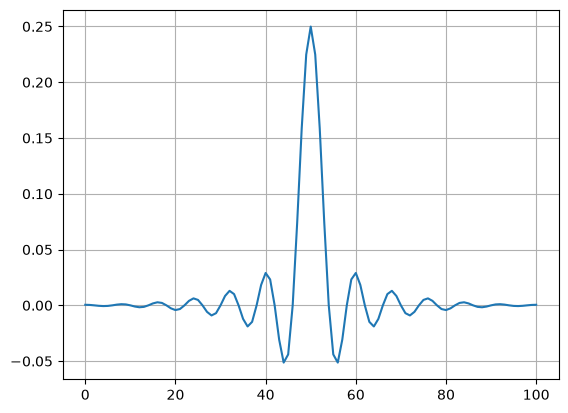

In [11]:
#########PLOTANDO OS COEFICIENTES DO FILTRO#########

plt.plot(h)
plt.grid()

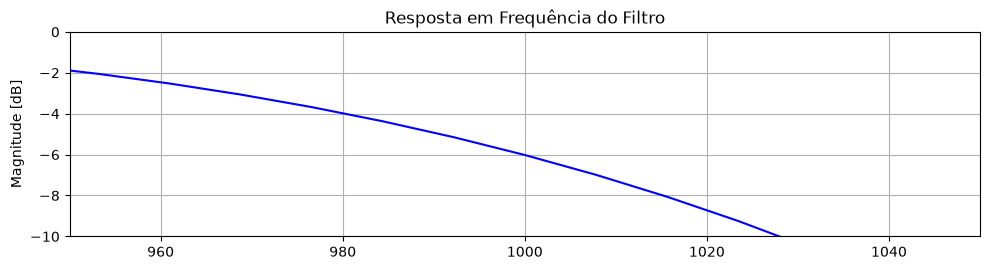

In [12]:
#########PLOTANDO A RESPOSTA EM FREQUÊNCIA DO FILTRO#########

#Calcula a resposta em frequência (w = frequências, h = resposta complexa)
w, H = signal.freqz(h, 1, fs=fs)

#Plota o gráfico da Magnitude (ganho em dB) e da Fase
plt.figure(figsize=(10, 5))

# Subplot da Magnitude
plt.subplot(2, 1, 1)
plt.plot(w, 20 * np.log10(np.abs(H)), "b")
plt.title("Resposta em Frequência do Filtro")
plt.ylabel("Magnitude [dB]")

plt.xlim(950, 1050)
plt.ylim(-10, 0)

plt.grid()

'''# Subplot da Fase
plt.subplot(2, 1, 2)
plt.plot(w, np.unwrap(np.angle(H)) * (180 / np.pi), "r")
plt.xlabel("Frequência [Hz]")
plt.ylabel("Fase [graus]")
plt.xlim(0, 1200)

plt.grid()'''

plt.tight_layout()
plt.show()